In [7]:
import numpy as np                # np  → fast maths & arrays
import pandas as pd               # pd  → tables & data manipulation
import matplotlib.pyplot as plt   # plt → basic plotting
import seaborn as sns             # sns → beautiful statistical plots
import warnings                   # suppress non-critical alerts

warnings.simplefilter('ignore')   # hide warning messages so output is clean
sns.set_style('whitegrid')        # give all charts a clean white background with grid

In [8]:
sample_data = {
    'RideID':   [101, 102, 103, 104, 105],
    'Pickup':   ['Airport', 'City', 'Airport', 'City', 'Airport'],
    'Duration': [35, 22, 48, 15, 60],
    'Status':   ['Completed', 'Cancelled', 'Completed', 'Completed', 'No Cars']
}

In [9]:
sample_df = pd.DataFrame(sample_data)
sample_df

,RideID,Pickup,Duration,Status
0,101,Airport,35,Completed
1,102,City,22,Cancelled
2,103,Airport,48,Completed
3,104,City,15,Completed
4,105,Airport,60,No Cars


In [10]:
sample_df['Duration'].mean()

np.float64(36.0)

In [11]:
df = pd.read_csv('/content/uber-data (8).csv')

In [12]:
df.head()

,Request id,Pickup point,Driver id,Status,Request timestamp,Drop timestamp
0,619,Airport,1.0,Trip Completed,2016-11-07 11:51:00,2016-11-07 13:00:00
1,867,Airport,1.0,Trip Completed,2016-11-07 17:57:00,2016-11-07 18:47:00
2,1807,City,1.0,Trip Completed,2016-12-07 09:17:00,2016-12-07 09:58:00
3,2532,Airport,1.0,Trip Completed,2016-12-07 21:08:00,2016-12-07 22:03:00
4,3112,City,1.0,Trip Completed,2016-07-13 08:33:16,2016-07-13 09:25:47


In [13]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6745 entries, 0 to 6744
Data columns (total 6 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Request id         6745 non-null   int64  
 1   Pickup point       6745 non-null   object 
 2   Driver id          4095 non-null   float64
 3   Status             6745 non-null   object 
 4   Request timestamp  6745 non-null   object 
 5   Drop timestamp     2831 non-null   object 
dtypes: float64(1), int64(1), object(4)
memory usage: 316.3+ KB


In [14]:
df['Request timestamp'] = pd.to_datetime(df['Request timestamp'], errors='coerce')
df['Drop timestamp'] = pd.to_datetime(df['Drop timestamp'], errors='coerce')

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6745 entries, 0 to 6744
Data columns (total 6 columns):
 #   Column             Non-Null Count  Dtype         
---  ------             --------------  -----         
 0   Request id         6745 non-null   int64         
 1   Pickup point       6745 non-null   object        
 2   Driver id          4095 non-null   float64       
 3   Status             6745 non-null   object        
 4   Request timestamp  6745 non-null   datetime64[ns]
 5   Drop timestamp     2831 non-null   datetime64[ns]
dtypes: datetime64[ns](2), float64(1), int64(1), object(2)
memory usage: 316.3+ KB


In [15]:
df['Status'].value_counts()

,count
Status,
Trip Completed,2831
No Cars Available,2650
Cancelled,1264


In [16]:
df['Status'].value_counts(normalize=True)

,proportion
Status,
Trip Completed,0.419718
No Cars Available,0.392884
Cancelled,0.187398


In [17]:
df['RequestHour'] = df['Request timestamp'].dt.hour
df.head()

,Request id,Pickup point,Driver id,Status,Request timestamp,Drop timestamp,RequestHour
0,619,Airport,1.0,Trip Completed,2016-11-07 11:51:00,2016-11-07 13:00:00,11
1,867,Airport,1.0,Trip Completed,2016-11-07 17:57:00,2016-11-07 18:47:00,17
2,1807,City,1.0,Trip Completed,2016-12-07 09:17:00,2016-12-07 09:58:00,9
3,2532,Airport,1.0,Trip Completed,2016-12-07 21:08:00,2016-12-07 22:03:00,21
4,3112,City,1.0,Trip Completed,2016-07-13 08:33:16,2016-07-13 09:25:47,8


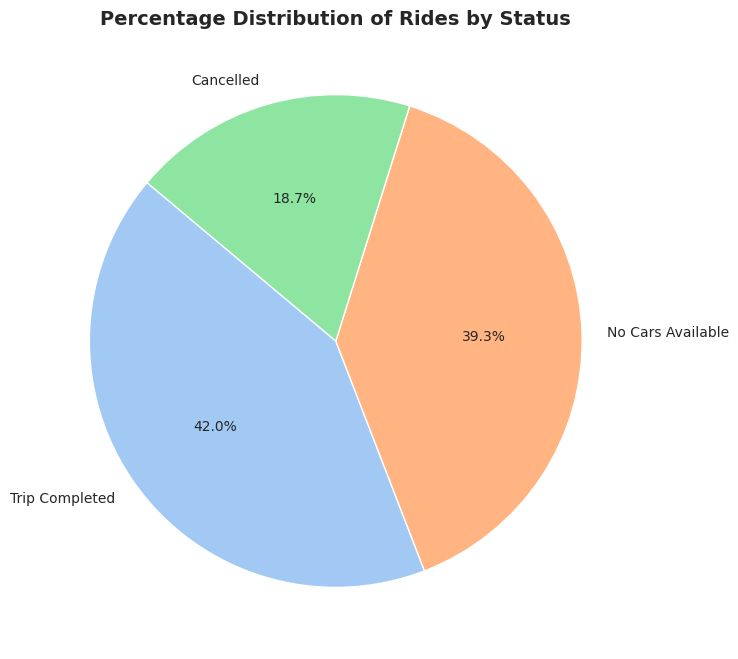

In [18]:
# Get the counts for each status
status_counts = df['Status'].value_counts()

# Create a pie chart
plt.figure(figsize=(8, 8))
plt.pie(status_counts, labels=status_counts.index, autopct='%1.1f%%', startangle=140, colors=sns.color_palette('pastel'))
plt.title('Percentage Distribution of Rides by Status', fontsize=14, fontweight='bold')
plt.show()

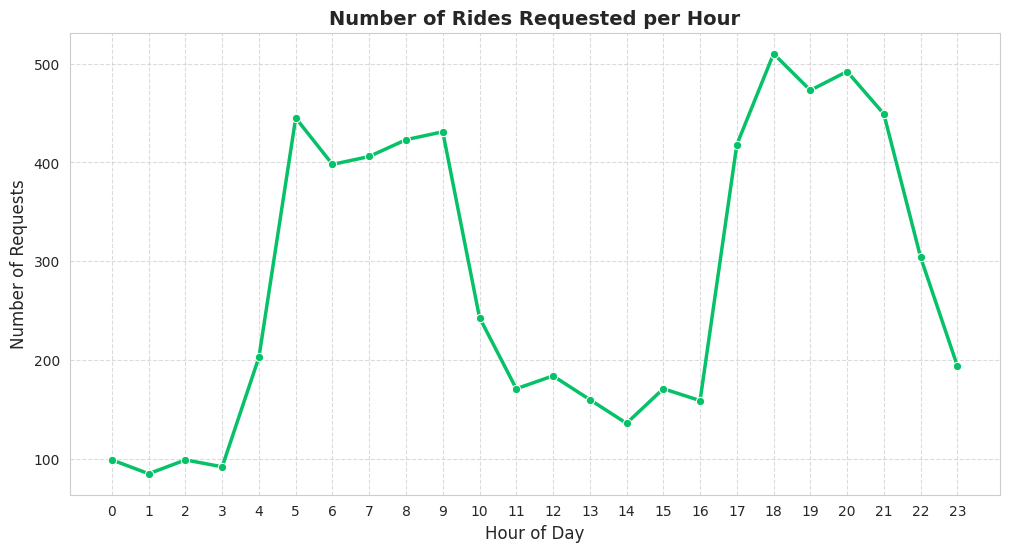

In [19]:
# Aggregate requests per hour
rides_per_hour = df['RequestHour'].value_counts().sort_index()

# Create a line plot comparing rides requested per hour
plt.figure(figsize=(12, 6))
sns.lineplot(x=rides_per_hour.index, y=rides_per_hour.values, marker='o', color='#06C167', linewidth=2.5)
plt.title('Number of Rides Requested per Hour', fontsize=14, fontweight='bold')
plt.xlabel('Hour of Day', fontsize=12)
plt.ylabel('Number of Requests', fontsize=12)
plt.xticks(range(0, 24))
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()

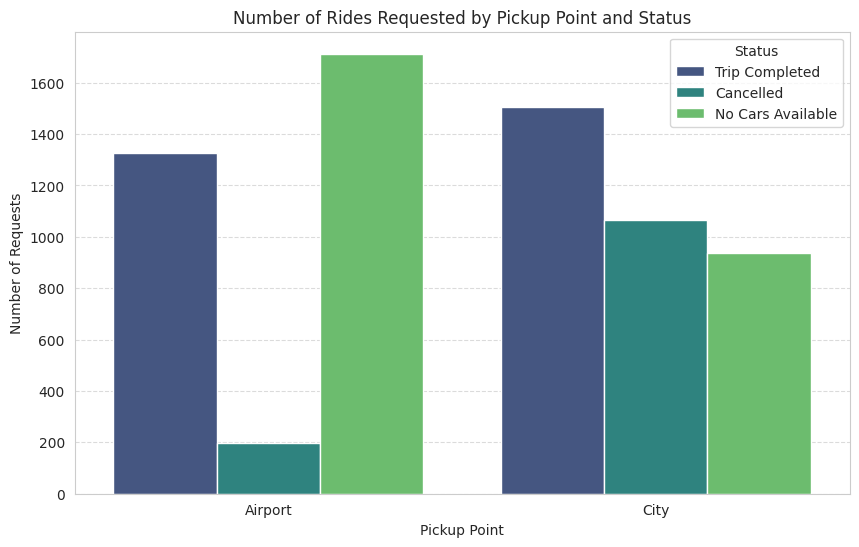

In [20]:
plt.figure(figsize=(10, 6))
sns.countplot(data=df, x='Pickup point', hue='Status', palette='viridis')
plt.title('Number of Rides Requested by Pickup Point and Status')
plt.xlabel('Pickup Point')
plt.ylabel('Number of Requests')
plt.legend(title='Status')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

In [21]:
## no of rides by Request hour and status
rides_by_hour_and_status = df.groupby(['RequestHour', 'Status']).size().unstack().fillna(0)

In [22]:
df.groupby(['RequestHour', 'Status']).size().unstack().fillna(0)

Status,Cancelled,No Cars Available,Trip Completed
RequestHour,,,
0,3,56,40
1,4,56,25
2,5,57,37
3,2,56,34
4,51,74,78
5,176,84,185
6,145,86,167
7,169,63,174
8,178,90,155


In [23]:
hourly_status= df.groupby(['RequestHour', 'Status']).size().unstack().fillna(0)

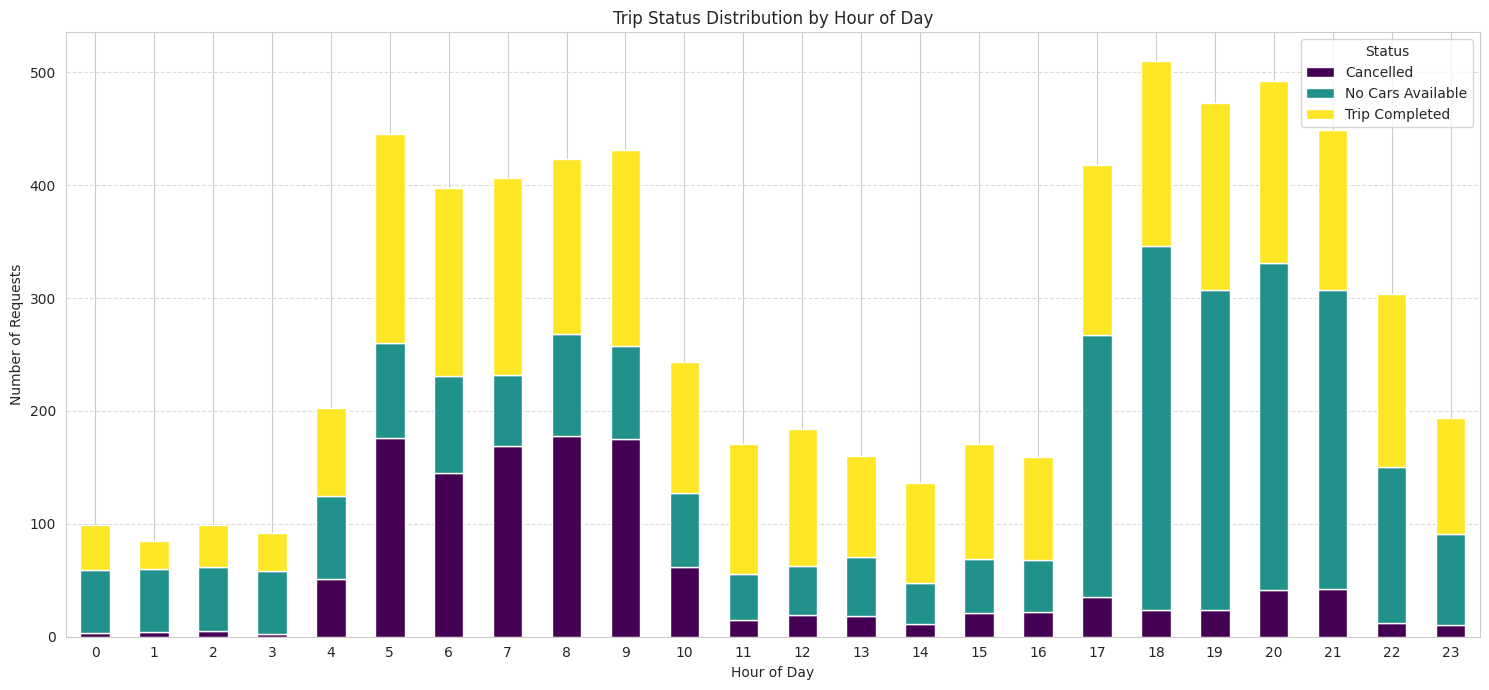

In [24]:
hourly_status.plot(kind='bar', stacked=True, figsize=(15, 7), colormap='viridis')
plt.title('Trip Status Distribution by Hour of Day')
plt.xlabel('Hour of Day')
plt.ylabel('Number of Requests')
plt.xticks(rotation=0)
plt.legend(title='Status')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

In [25]:
hourly_status_city = df[df['Pickup point'] == 'City'].groupby(['RequestHour', 'Status'])['Request id'].count().unstack().fillna(0)

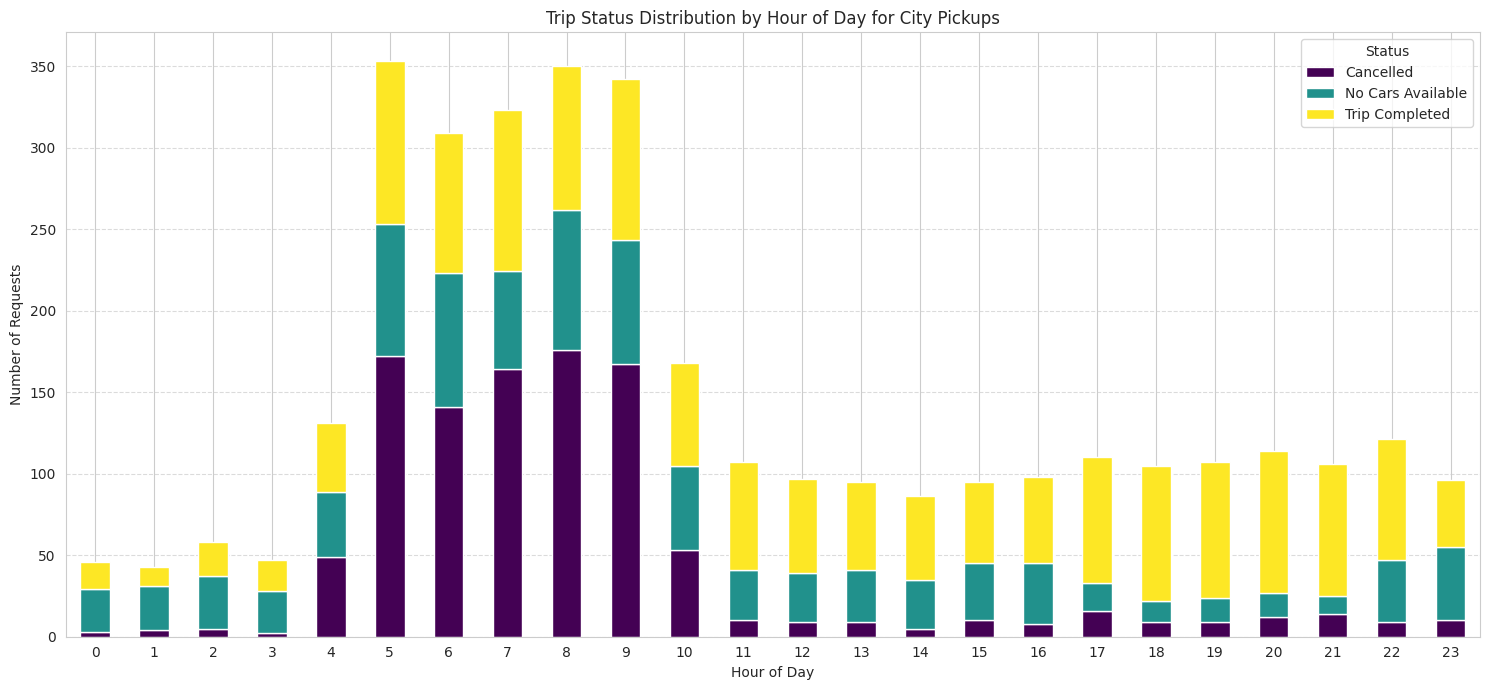

In [26]:
#airport data
hourly_status_city.plot(kind='bar', stacked=True, figsize=(15, 7), colormap='viridis')
plt.title('Trip Status Distribution by Hour of Day for City Pickups')
plt.xlabel('Hour of Day')
plt.ylabel('Number of Requests')
plt.xticks(rotation=0)
plt.legend(title='Status')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()